# 08 · Model Explainability

Why does the final model give an attempt a high or low chance? Three views from lesson 16:

1. **Feature importance**: which features the trees rely on most overall
2. **Partial dependence**: how the predicted probability changes as one feature changes, with the others kept as they are
3. **SHAP values**: how much each feature pushes each individual attempt's score up or down

In [1]:
import sys, json, pickle
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from clean import load_attempts
from prep import split, RANDOM_STATE, NUMERIC, CATEGORICAL

from sklearn.inspection import PartialDependenceDisplay

sns.set_theme(style='whitegrid')
attempts = load_attempts()
X_train, X_test, y_train, y_test = split(attempts)
del attempts

final = pickle.load(open('../data/final_model.pkl', 'rb'))          # saved in notebook 07
best_name = json.load(open('../results/threshold.json'))['final_model']
feature_names = final.named_steps['prep'].get_feature_names_out()
print(best_name, '|', len(feature_names), 'features after preprocessing')

Gradient Boosting | 59 features after preprocessing


## 1. Feature importance

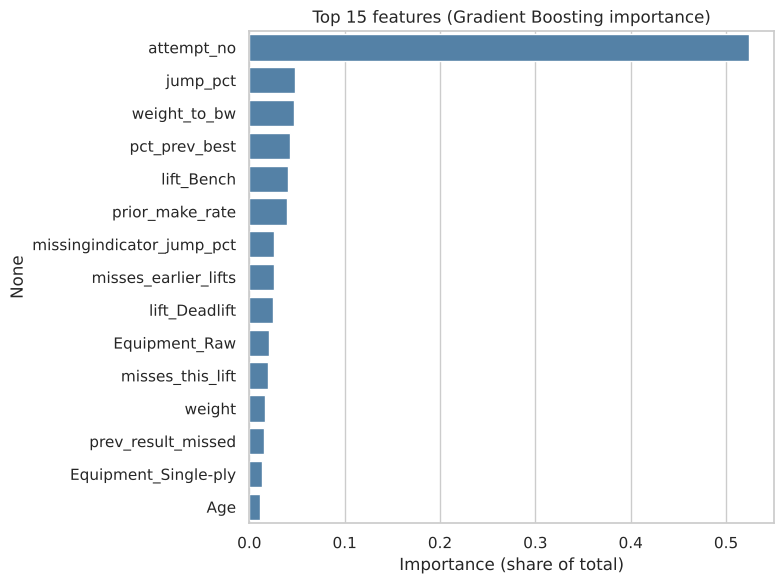

attempt_no                   0.5241
jump_pct                     0.0474
weight_to_bw                 0.0471
pct_prev_best                0.0425
lift_Bench                   0.0405
prior_make_rate              0.0392
missingindicator_jump_pct    0.0262
misses_earlier_lifts         0.0259
lift_Deadlift                0.0253
Equipment_Raw                0.0202
misses_this_lift             0.0201
weight                       0.0160
prev_result_missed           0.0155
Equipment_Single-ply         0.0137
Age                          0.0115
dtype: float64

In [2]:
imp = (pd.Series(final.named_steps['model'].feature_importances_, index=feature_names)
       .sort_values(ascending=False))
top = imp.head(15)
plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index, color='steelblue')
plt.title(f'Top 15 features ({best_name} importance)')
plt.xlabel('Importance (share of total)')
plt.tight_layout(); plt.show()
imp.head(15).round(4)

In [3]:
# importance grouped back to the original columns (one-hot levels and missing flags added to their column)
original = {}
for name, value in imp.items():
    base = name.replace('missingindicator_', '')
    if base not in NUMERIC:
        base = next((c for c in CATEGORICAL if base.startswith(c + '_')), base)
    original[base] = original.get(base, 0) + value
grouped = pd.Series(original).sort_values(ascending=False)
grouped.round(4)

attempt_no              0.5241
jump_pct                0.0736
lift                    0.0721
weight_to_bw            0.0471
pct_prev_best           0.0434
prior_make_rate         0.0398
Equipment               0.0340
misses_earlier_lifts    0.0259
jump_kg                 0.0212
prev_result             0.0206
misses_this_lift        0.0201
weight                  0.0160
Age                     0.0119
Event                   0.0108
BodyweightKg            0.0105
days_since_last         0.0105
meet_country            0.0081
n_prior_meets           0.0065
tested                  0.0021
Sex                     0.0019
dtype: float64

**`attempt_no` dominates (52% of the total importance):** whether it is an opener, second or third attempt explains more than everything else together. Then come `jump_pct` (7%), `lift` (7%), `weight_to_bw` (5%), `pct_prev_best` (4%), `prior_make_rate` (4%) and `Equipment` (3%).
`Sex` (0.2%), `tested` (0.2%) and `n_prior_meets` (0.7%) barely matter once the rest is known.

## 2. Partial dependence: how the score moves with each feature

Computed on 3,000 training attempts that are **second or third attempts by lifters with an earlier meet**, so every feature has a value.

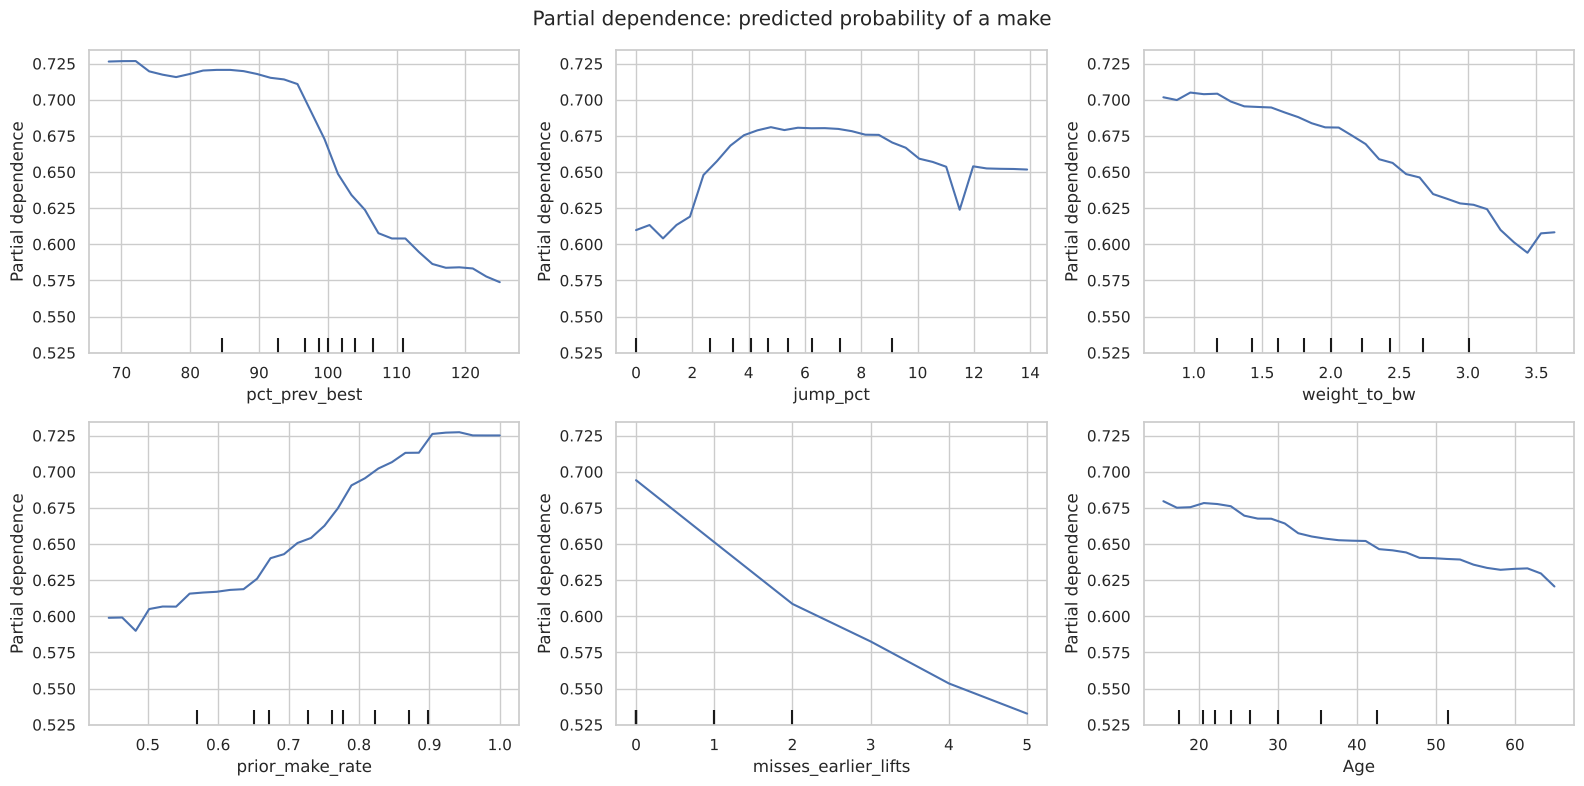

In [4]:
pool = X_train[(X_train['attempt_no'] > 1) & X_train['pct_prev_best'].notna() & X_train['jump_pct'].notna()
               & X_train['Age'].notna() & X_train['prior_make_rate'].notna()]
sample = pool.sample(3000, random_state=RANDOM_STATE).copy()
num = ['pct_prev_best', 'jump_pct', 'weight_to_bw', 'prior_make_rate', 'misses_earlier_lifts', 'Age']
sample[num] = sample[num].astype(float)                 # partial dependence needs float columns

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
PartialDependenceDisplay.from_estimator(final, sample, num, ax=axes.ravel(), grid_resolution=30,
                                        percentiles=(0.02, 0.98))
plt.suptitle('Partial dependence: predicted probability of a make')
plt.tight_layout(); plt.show()

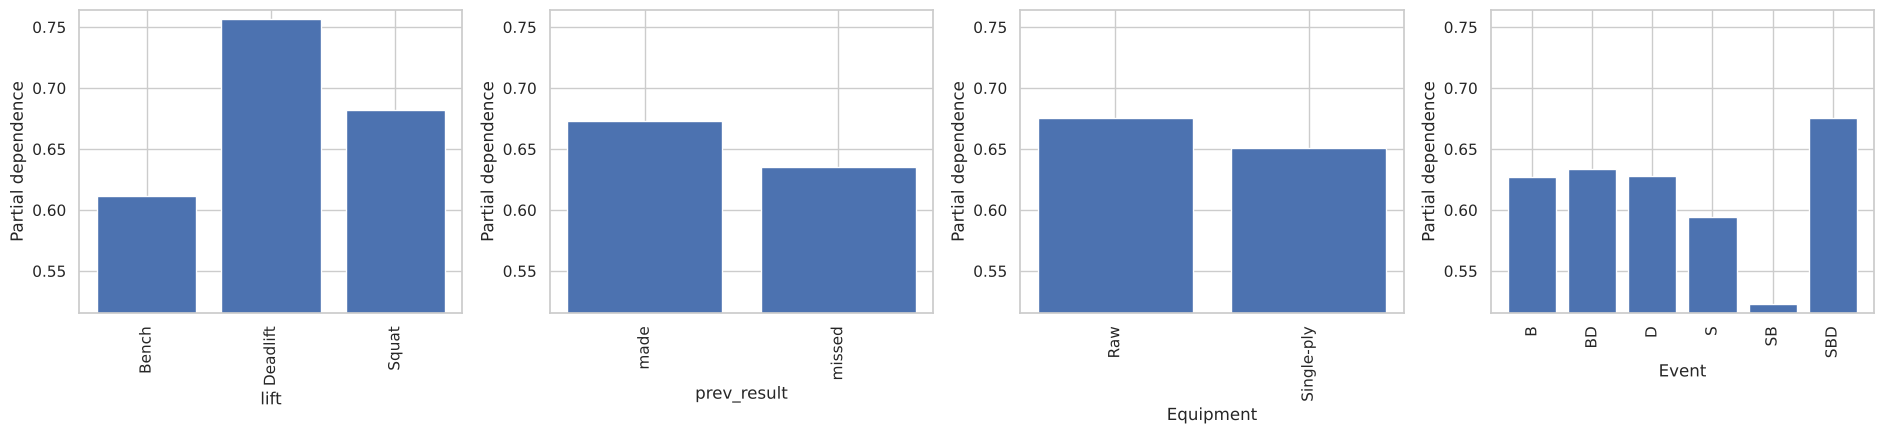

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.5))
PartialDependenceDisplay.from_estimator(final, sample, ['lift', 'prev_result', 'Equipment', 'Event'],
                                        categorical_features=['lift', 'prev_result', 'Equipment', 'Event'], ax=axes)
plt.tight_layout(); plt.show()

In [6]:
# the same numbers as a table, for the write-up
pd_rows = {}
for feat, grid in [('pct_prev_best', [85, 90, 95, 100, 102.5, 105, 110]), ('jump_pct', [0, 2.5, 5, 7.5, 10, 15])]:
    for v in grid:
        tmp = sample.copy(); tmp[feat] = float(v)
        pd_rows[(feat, v)] = final.predict_proba(tmp)[:, 1].mean()
pd.Series(pd_rows).round(3).rename('average predicted P(make)')

pct_prev_best  85.0     0.721
               90.0     0.718
               95.0     0.713
               100.0    0.671
               102.5    0.643
               105.0    0.624
               110.0    0.604
jump_pct       0.0      0.610
               2.5      0.649
               5.0      0.681
               7.5      0.680
               10.0     0.659
               15.0     0.648
Name: average predicted P(make), dtype: float64

(for second and third attempts by lifters with history, average predicted probability)

- **pct_prev_best:** flat at about **0.72 up to 95%** of the earlier best, then a sharp drop: 0.67 at 100%, 0.62 at 105%, 0.60 at 110%. The old best is a real barrier.
- **jump_pct:** 0.61 for no jump, rising to **0.68 for 4–8% jumps**, then 0.65 for big jumps: the small-jump pattern from the EDA, now with every other feature held fixed.
- **weight_to_bw:** falls from 0.70 at 1× bodyweight to 0.60 at 3.5×: very heavy lifts relative to bodyweight are missed more.
- **prior_make_rate:** from 0.60 (lifters who made half their earlier attempts) to **0.73** (90%+): consistent lifters stay consistent.
- **misses_earlier_lifts:** 0.695 with no earlier misses, 0.65 after one, 0.61 after two, 0.53 after five: a bad day carries over.
- **lift:** deadlift 0.76, squat 0.68, bench 0.61. **prev_result:** 0.67 after a make vs 0.64 after a miss. **Equipment:** raw 0.68 vs single-ply 0.65.

## 3. SHAP values

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


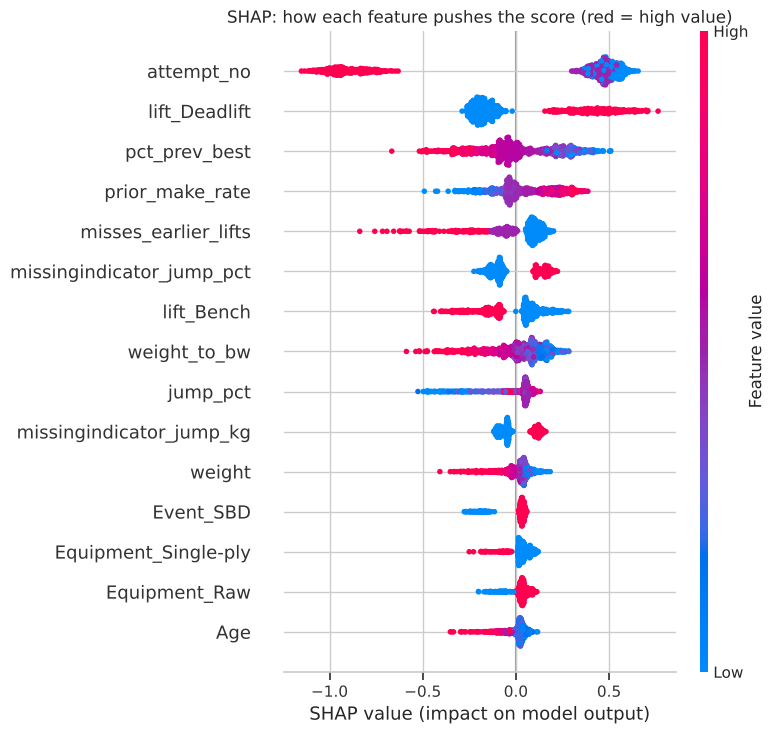

In [7]:
import shap

X_test_t = pd.DataFrame(final.named_steps['prep'].transform(X_test), columns=feature_names)
shap_sample = X_test_t.sample(1000, random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(final.named_steps['model'])
shap_values = explainer.shap_values(shap_sample)
if isinstance(shap_values, list):            # Random Forest returns one array per class
    shap_values = shap_values[1]
elif np.ndim(shap_values) == 3:
    shap_values = shap_values[:, :, 1]

shap.summary_plot(shap_values, shap_sample, max_display=15, show=False)
plt.title('SHAP: how each feature pushes the score (red = high value)')
plt.tight_layout(); plt.show()

In [8]:
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_names).sort_values(ascending=False)
mean_abs.head(10).round(4)

attempt_no                   0.6186
lift_Deadlift                0.2559
pct_prev_best                0.1678
prior_make_rate              0.1286
misses_earlier_lifts         0.1243
missingindicator_jump_pct    0.1229
lift_Bench                   0.1217
weight_to_bw                 0.1173
jump_pct                     0.0862
missingindicator_jump_kg     0.0848
dtype: float64

### One attempt, explained

In [9]:
proba = final.predict_proba(X_test)[:, 1]
# a typical risky case: a third attempt by a lifter with history, at most 10% above their earlier best, with a normal jump (0-10%)
typical = ((X_test['attempt_no'] == 3) & X_test['pct_prev_best'].between(100, 110) & X_test['jump_pct'].between(0, 10)).values
candidates = np.where(typical)[0]
i = candidates[np.argmin(proba[candidates])]   # the riskiest of these in the test set
print(f'Predicted probability of a make {proba[i]:.2f} | actually made: {bool(y_test.iloc[i])}')
print(X_test.iloc[i][['lift', 'attempt_no', 'weight', 'pct_prev_best', 'prev_result', 'jump_kg', 'misses_this_lift',
                      'misses_earlier_lifts', 'prior_make_rate', 'Equipment', 'Sex']])
sv = explainer.shap_values(X_test_t.iloc[[i]])
sv = sv[1][0] if isinstance(sv, list) else (sv[0, :, 1] if np.ndim(sv) == 3 else sv[0])
contrib = pd.Series(sv, index=feature_names).sort_values(key=abs, ascending=False).head(8)
contrib.round(3)

Predicted probability of a make 0.05 | actually made: False
lift                         Bench
attempt_no                       3
weight                       302.5
pct_prev_best           108.035721
prev_result                 missed
jump_kg                       22.5
misses_this_lift                 1
misses_earlier_lifts             0
prior_make_rate           0.406593
Equipment               Single-ply
Sex                              M
Name: 3970594, dtype: object


attempt_no        -0.923
jump_kg           -0.508
pct_prev_best     -0.445
prior_make_rate   -0.400
weight_to_bw      -0.326
weight            -0.324
Event_SBD         -0.309
Age               -0.230
dtype: float64

In [10]:
grouped.round(4).to_csv('../results/feature_importance.csv', header=['importance'])

## What the model learned

**Overall importance:** the attempt number (52%) leads by far, followed by the jump (7%), the lift (7%), weight ÷ bodyweight (5%), weight vs earlier best (4%), the lifter's earlier make rate (4%) and equipment (3%).

**Partial dependence** shows *how* they act:

- The **earlier best is a barrier**: the chance stays near 72% up to 95% of it, then falls to 60% at 110%.
- **Normal jumps (4–8%) score best**; no jump or a tiny jump scores lowest, because it signals a hard previous attempt.
- **Consistency carries over:** a lifter who made 90%+ of attempts at earlier meets scores 13 points higher than one who made half, and each miss earlier in the meet lowers the next attempt's chance.
- **Deadlift > squat > bench** at equal settings.

**SHAP** adds the per-attempt view. The attempt number gives the biggest push (mean |SHAP| 0.62 on the log-odds scale), followed by the deadlift (0.26), weight vs earlier best (0.17), earlier make rate (0.13) and misses on earlier lifts (0.12).
The example above, a single-ply bench third attempt at 108% of the earlier best after a missed second attempt by a lifter who made only 41% of attempts before, gets 5%: every one of those factors pushes the score down. It was missed.

All three views agree with the EDA and with the Logistic Regression odds ratios, so the drivers are consistent across models.